In [2]:
import ee
import folium
import geopandas as gd
import matplotlib.pyplot as plt
import numpy as np
import rasterio

print("\n-------ALL LIBRARIES LOADED SUCCESSFULLY--------")
print(f"rasterio version: {rasterio.__version__}")
print(f"geopandas version: {gd.__version__}")
print(f"folium version: {folium.__version__}")
print(f"google earth version: {ee.__version__}")


-------ALL LIBRARIES LOADED SUCCESSFULLY--------
rasterio version: 1.5.1
geopandas version: 1.1.4
folium version: 0.20.0
google earth version: 1.7.40


In [5]:
try:
    ee.Initialize(project="ee-undergrad-thesis-509519")
    print("successfully loaded")
except Exception as e:
    print(f"nope not loaded {e}")

nope not loaded Please authorize access to your Earth Engine account by running

earthengine authenticate

in your command line, or ee.Authenticate() in Python, and then retry.


In [7]:
ee.Authenticate()

True

In [9]:
try:
    ee.Initialize(project="ee-undergrad-thesis-509519")
    print("successfully loaded")
except Exception as e:
    print(f"not loaded {e}")

successfully loaded


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


In [1]:
import ee

ee.Initialize(project="ee-undergrad-thesis-509519")

roi = ee.Geometry.BBox(37.50, 47.00, 38.00, 47.50)

s2_collection = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(roi)
    .filterDate("2023-01-01", "2023-12-31")
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 10))
    .sort("system:time_start", False)
)

count = s2_collection.size().getInfo()
print(f"Total matching Sentinel-2 scenes found: {count}")

if count > 0:
    selected_image = s2_collection.first()

    image_id = selected_image.get("system:index").getInfo()
    cloud_pct = selected_image.get("CLOUDY_PIXEL_PERCENTAGE").getInfo()
    date_str = ee.Date(selected_image.get("system:time_start")).format("YYYY-MM-dd").getInfo()

    print(f"\n--- SELECTED SCENE METADATA ---")
    print(f"Image ID:      {image_id}")
    print(f"Acquisition:   {date_str}")
    print(f"Cloud Cover:   {cloud_pct:.2f}%")
else:
    print("No images found matching your filter criteria. Try expanding the date range or cloud threshold.")

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Total matching Sentinel-2 scenes found: 31

--- SELECTED SCENE METADATA ---
Image ID:      20231114T083119_20231114T083257_T37TCN
Acquisition:   2023-11-14
Cloud Cover:   0.24%


In [1]:
import ee

ee.Initialize()

roi = ee.Geometry.BBox(36.1,36.1,36.3,36.3)
TARGET_BANDS = ['B2','B3','B4','B8','B11','B12']
s2_collection = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(roi)
    .filterDate('2024-01-01','2024-06-01')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE',10))
    .select(TARGET_BANDS)
    .sort('system:time_start',False)
)

latest_scene = s2_collection.first()
selected_bands = latest_scene.bandNames().getInfo()
scene_date = ee.Date(latest_scene.get('system:time_start')).format('YYYY-MM-dd').getInfo()

print(f"acquisition date: {scene_date}")
print(f"selected bands({len(selected_bands)}):{selected_bands}")

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


acquisition date: 2024-05-29
selected bands(6):['B2', 'B3', 'B4', 'B8', 'B11', 'B12']


In [ ]:
import ee
import numpy as np
ee.Initialize()
roi = ee.Geometry.BBox(36.1,36.1,36.3,36.3)
TARGET_BANDS = ['B2','B3','B4','B8','B11','B12']

image = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(roi)
    .filterDate('2024-01-01','2024-06-01')
    
)

In [1]:
import ee
import numpy as np
import matplotlib.pyplot as plt

ee.Initialize()

roi = ee.Geometry.BBox(36.1,36.1,36.3,36.3)
TARGET_BANDS = ['B2','B3','B4','B8','B11','B12']
band_idx = {name: idx for idx, name in enumerate(TARGET_BANDS)}

image = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(roi)
    .filterDate('2024-01-01', '2024-06-01')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
    .select(TARGET_BANDS)
    .sort('system:time_start', False)
    .first()
)

pixel_data = image.sampleRectangle(region = roi, defualtValue=0)
band_arrays = [np.array(pixel_data.get(b).getInfor()) for b in TARGET_BANDS]

arr_float = np.clip(arr_3d / 10000.0,0,1) # whats normalize surface reflectance

b2_blue  = arr_float[:, :, band_idx['B2']]
b3_green = arr_float[:, :, band_idx['B3']]
b4_red   = arr_float[:, :, band_idx['B4']]
b8_nir   = arr_float[:, :, band_idx['B8']]
b11_swir = arr_float[:, :, band_idx['B11']]

epsilon = 1e-10
ndbi = np.clip((b11_swir - b8_nir) / (b11_swir + b8_nir + eps), -1.0, 1.0)
ndvi = np.clip((b8_nir - b4_red) / (b8_nir + b4_red + eps), -1.0, 1.0)

feature_tensor = np.concatentate([
    arr_float,
    np.expand_dims(ndbi, axis=-1),
    np.expand_dims(ndvi, axis=-1) # does this mean its added on the back
], axis=-1)
print(f"validated feature tensor shape: {feature_tensor.shape}")

rgb_composite = np.clip(np.dstack([b4_red, b3_green, b2_blue]) * 2.5,0,1)#whats the 2.5 for
fig, axes = plt.subplots(2,2,figsize=(14,12)) # makes 2 x 2 contrast grid

im1 = axes[0,1].imshow(b8_nir, cmap = 'viridis')
axes[0,1].set_title("NIR (b8) - reflectance response", fontsize = 12, fontweight = 'bold')
axes[0, 1].axis('off')
plt.colorbar(im1, ax=axes[0, 1], fraction=0.046, pad=0.04)

im2 = axes[1, 0].imshow(b11_swir, cmap='magma')# Structural Concrete
axes[1, 0].set_title("SWIR-1 (B11) - Concrete/Urban Response", fontsize=12, fontweight='bold')
axes[1, 0].axis('off')
plt.colorbar(im2, ax=axes[1, 0], fraction=0.046, pad=0.04)

im3 = axes[1, 1].imshow(ndbi, cmap='coolwarm', vmin=-0.5, vmax=0.5) # NDBI Heatmap
axes[1, 1].set_title("Derived NDBI Index [(B11-B8)/(B11+B8)]", fontsize=12, fontweight='bold')

axes[1, 1].axis('off')
plt.colorbar(im3, ax=axes[1, 1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

EEException: Please authorize access to your Earth Engine account by running

earthengine authenticate

in your command line, or ee.Authenticate() in Python, and then retry.

validated feature tensor shape: (335, 335, 8)


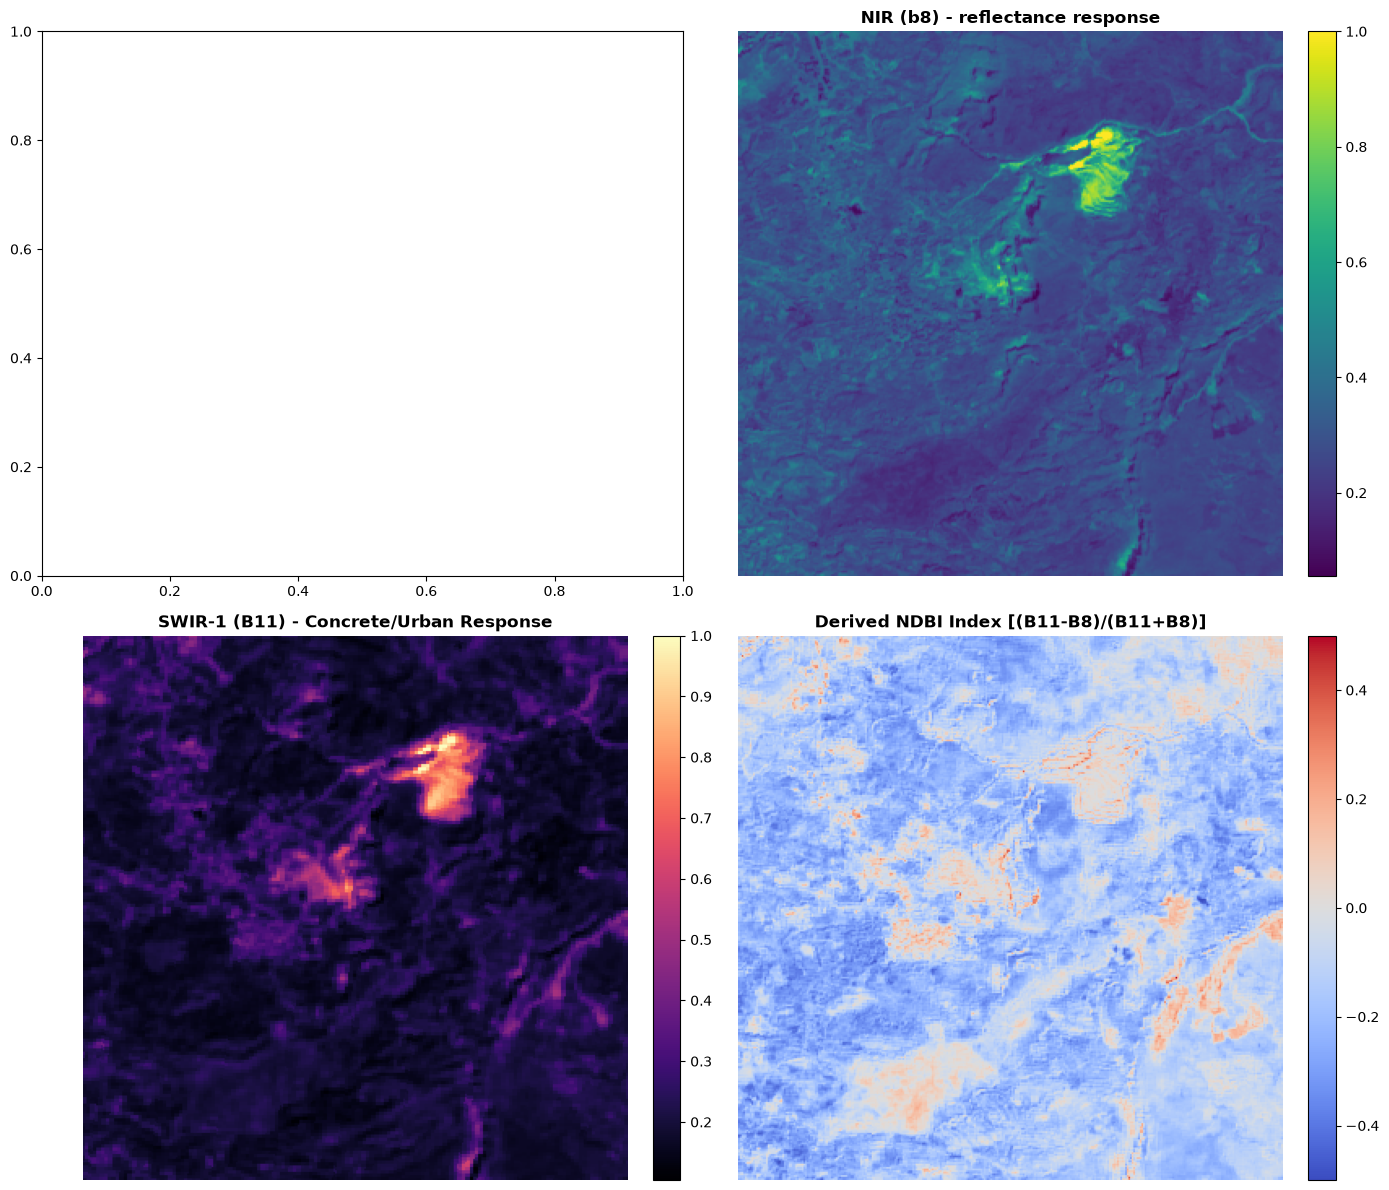

In [11]:
import ee
import numpy as np
import matplotlib.pyplot as plt

ee.Initialize(project="ee-undergrad-thesis-509519")

roi = ee.Geometry.BBox(36.15, 36.15, 36.18, 36.18)
TARGET_BANDS = ['B2','B3','B4','B8','B11','B12']
band_idx = {name: idx for idx, name in enumerate(TARGET_BANDS)}

image = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(roi)
    .filterDate('2024-01-01', '2024-06-01')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
    .select(TARGET_BANDS)
    .sort('system:time_start', False)
    .first()
    .reproject(crs='EPSG:4326', scale=10)
)

pixel_data = image.sampleRectangle(region = roi, defaultValue=0)
band_arrays = [np.array(pixel_data.get(b).getInfo()) for b in TARGET_BANDS]
arr_3d = np.stack(band_arrays, axis=-1)

arr_float = np.clip(arr_3d / 10000.0,0,1) # whats normalize surface reflectance

b2_blue  = arr_float[:, :, band_idx['B2']]
b3_green = arr_float[:, :, band_idx['B3']]
b4_red   = arr_float[:, :, band_idx['B4']]
b8_nir   = arr_float[:, :, band_idx['B8']]
b11_swir = arr_float[:, :, band_idx['B11']]

eps = 1e-10
ndbi = np.clip((b11_swir - b8_nir) / (b11_swir + b8_nir + eps), -1.0, 1.0)
ndvi = np.clip((b8_nir - b4_red) / (b8_nir + b4_red + eps), -1.0, 1.0)

feature_tensor = np.concatenate([
    arr_float,
    np.expand_dims(ndbi, axis=-1),
    np.expand_dims(ndvi, axis=-1) # does this mean its added on the back
], axis=-1)
print(f"validated feature tensor shape: {feature_tensor.shape}")

rgb_composite = np.clip(np.dstack([b4_red, b3_green, b2_blue]) * 2.5,0,1)#whats the 2.5 for
fig, axes = plt.subplots(2,2,figsize=(14,12)) # makes 2 x 2 contrast grid

im1 = axes[0,1].imshow(b8_nir, cmap = 'viridis')
axes[0,1].set_title("NIR (b8) - reflectance response", fontsize = 12, fontweight = 'bold')
axes[0, 1].axis('off')
plt.colorbar(im1, ax=axes[0, 1], fraction=0.046, pad=0.04)

im2 = axes[1, 0].imshow(b11_swir, cmap='magma')# Structural Concrete
axes[1, 0].set_title("SWIR-1 (B11) - Concrete/Urban Response", fontsize=12, fontweight='bold')
axes[1, 0].axis('off')
plt.colorbar(im2, ax=axes[1, 0], fraction=0.046, pad=0.04)

im3 = axes[1, 1].imshow(ndbi, cmap='coolwarm', vmin=-0.5, vmax=0.5) # NDBI Heatmap
axes[1, 1].set_title("Derived NDBI Index [(B11-B8)/(B11+B8)]", fontsize=12, fontweight='bold')

axes[1, 1].axis('off')
plt.colorbar(im3, ax=axes[1, 1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [3]:
ee.Authenticate()

Enter verification code:  4/1AXlqoi459xsC7k5DywHc6au394Awu2FybHbDcwYtkUQM-nVsLT-OhBDGDZk



Successfully saved authorization token.
